<a href="https://colab.research.google.com/github/igornvidal/apollo_analytics_academy/blob/main/Dribles_Futebol.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- PRIMEIRAS LINHAS DO NOVO DATASET ---
   dribles_concluidos  dribles_tentados  taxa_sucesso_pct
0                35.0              73.1              47.9
1                35.0              78.0              44.9
2                36.0              64.2              56.1
3                36.0              73.9              48.7
4                36.0              89.1              40.4


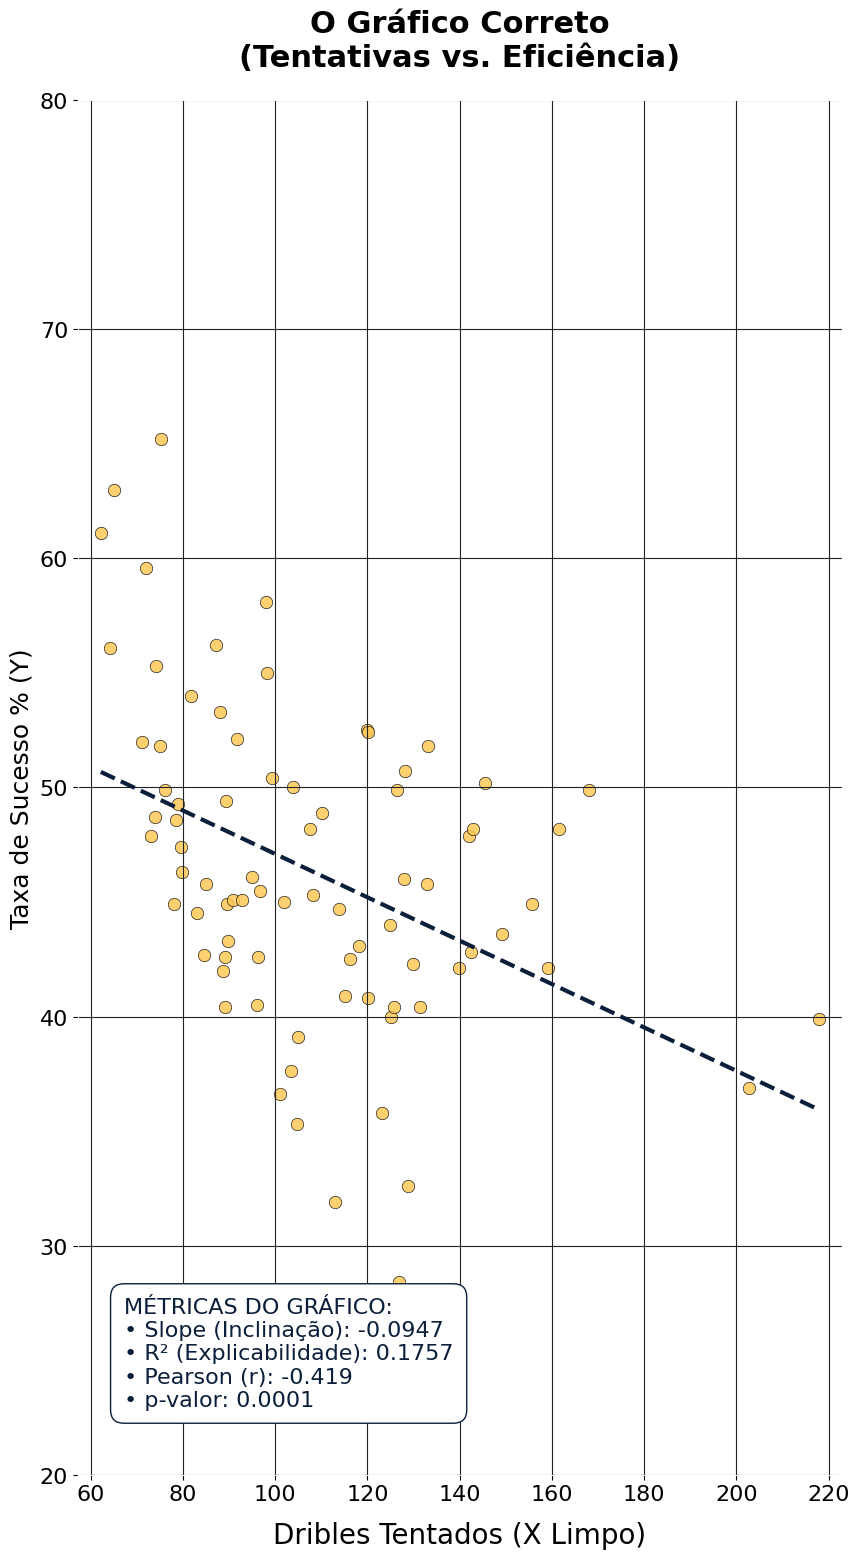

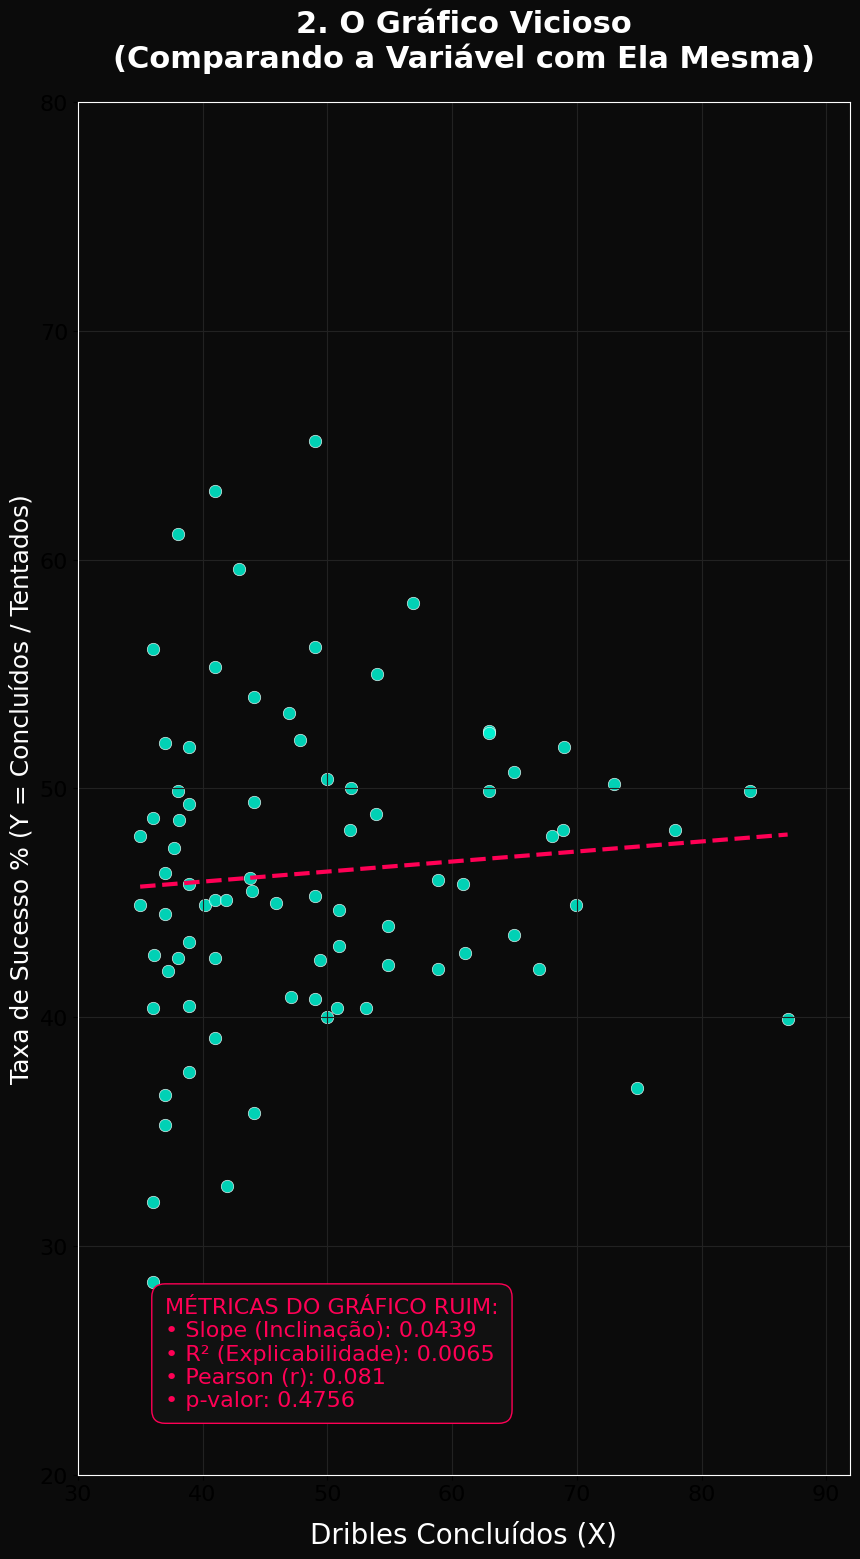

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats

# Configurações para Reels (Proporção 9:16 com fontes grandes)
#plt.style.use("dark_background")
plt.rcParams.update(
    {
        "font.size": 20,
        "axes.labelsize": 18,
        "axes.titlesize": 22,
        "xtick.labelsize": 16,"xtick.color": "black",
        "ytick.labelsize": 16,"ytick.color":"black"

        #"figure.autolayout": True,
    }
)

# 1. Dataset atualizado enviado pelo usuário
data = [
    (35.0,47.9), (35.0,44.9), (36.0,56.1), (36.0,48.7),
    (36.0,40.4), (36.0,31.9), (36.0,28.4), (36.1,42.7),
    (37.0,52.0), (37.0,46.3), (37.0,44.5), (37.0,36.6),
    (37.0,35.3), (37.2,42.0), (37.7,47.4), (38.0,61.1),
    (38.0,49.9), (38.0,42.6), (38.1,48.6), (38.9,51.8),
    (38.9,49.3), (38.9,45.8), (38.9,43.3), (38.9,40.5),
    (38.9,37.6), (40.2,44.9), (41.0,63.0), (41.0,55.3),
    (41.0,45.1), (41.0,42.6), (41.0,39.1), (41.9,45.1),
    (42.0,32.6), (42.9,59.6), (43.8,46.1), (44.0,45.5),
    (44.1,54.0), (44.1,49.4), (44.1,35.8), (45.9,45.0),
    (46.9,53.3), (47.1,40.9), (47.8,52.1), (49.0,65.2),
    (49.0,56.2), (49.0,45.3), (49.0,40.8), (49.4,42.5),
    (50.0,50.4), (50.0,40.0), (50.8,40.4), (50.9,44.7),
    (50.9,43.1), (51.8,48.2), (51.9,50.0), (53.1,40.4),
    (53.9,48.9), (54.0,55.0), (54.9,44.0), (54.9,42.3),
    (56.9,58.1), (58.9,46.0), (58.9,42.1), (60.9,45.8),
    (61.0,42.8), (63.0,52.5), (63.0,52.4), (63.0,49.9),
    (65.0,50.7), (65.0,43.6), (67.0,42.1), (68.0,47.9),
    (68.9,48.2), (69.0,51.8), (69.9,44.9), (73.0,50.2),
    (74.8,36.9), (77.9,48.2), (83.9,49.9), (86.9,39.9)
]

# 2. Criação do DataFrame com as colunas mapeadas
df = pd.DataFrame(data, columns=["dribles_concluidos", "taxa_sucesso_pct"])
df["dribles_tentados"] = np.round(
    (df["dribles_concluidos"] / (df["taxa_sucesso_pct"] / 100)), 1
)

# Reordenando as colunas: Concluídos, Tentados, Taxa de Sucesso
df = df[["dribles_concluidos", "dribles_tentados", "taxa_sucesso_pct"]]

print("--- PRIMEIRAS LINHAS DO NOVO DATASET ---")
print(df.head())

# -------------------------------------------------------------------------
# FIGURA 1: O Gráfico Correto (Volume Real de Tentativas vs. Taxa)
# -------------------------------------------------------------------------
slope1, intercept1, r1, p1, _ = stats.linregress(
    df["dribles_tentados"], df["taxa_sucesso_pct"]
)

fig1, ax1 = plt.subplots(figsize=(9, 16), facecolor="white")
ax1.set_facecolor("white")

ax1.scatter(
    df["dribles_tentados"],
    df["taxa_sucesso_pct"],
    color="#ffc857",
    s=80,
    alpha=0.85,
    edgecolor="black",
    linewidth=0.5,
)

x_line1 = np.linspace(df["dribles_tentados"].min(), df["dribles_tentados"].max(), 100)
ax1.plot(
    x_line1,
    slope1 * x_line1 + intercept1,
    color="#0b1f3b",
    linestyle="--",
    linewidth=3,
)

# Annotation
ax1.text(
    df["dribles_tentados"].min() + 5,
    23,
    f"MÉTRICAS DO GRÁFICO:\n"
    f"• Slope (Inclinação): {slope1:.4f}\n"
    f"• R² (Explicabilidade): {r1**2:.4f}\n"
    f"• Pearson (r): {r1:.3f}\n"
    f"• p-valor: {p1:.4f}",
    fontsize=16,
    color="#0b1f3b",
    bbox=dict(boxstyle="round,pad=0.6", facecolor="white", edgecolor="#0b1f3b"),
)

ax1.set_xlim(df["dribles_tentados"].min() - 5, df["dribles_tentados"].max() + 5)
ax1.set_ylim(20, 80)
ax1.set_xlabel("Dribles Tentados (X Limpo)", fontsize=20, labelpad=12, color ="black")
ax1.set_ylabel("Taxa de Sucesso % (Y)", fontsize=18,color ="black")
ax1.set_title(
    "O Gráfico Correto\n(Tentativas vs. Eficiência)",
    fontsize=22,
    pad=25,
    fontweight="bold", color="black"
)
ax1.grid(True, color="#222222", linestyle="-", linewidth=0.8)

plt.savefig("1_grafico_correto_tentados.png", dpi=300, bbox_inches="tight")
plt.show()

# -------------------------------------------------------------------------
# FIGURA 2: O Gráfico Ruim (Acoplamento Matemático)
# -------------------------------------------------------------------------
slope2, intercept2, r2, p2, _ = stats.linregress(
    df["dribles_concluidos"], df["taxa_sucesso_pct"]
)

fig2, ax2 = plt.subplots(figsize=(9, 16), facecolor="#0B0B0B")
ax2.set_facecolor("#0B0B0B")

ax2.scatter(
    df["dribles_concluidos"],
    df["taxa_sucesso_pct"],
    color="#00F5D4",
    s=80,
    alpha=0.85,
    edgecolor="white",
    linewidth=0.5,
)

x_line2 = np.linspace(df["dribles_concluidos"].min(), df["dribles_concluidos"].max(), 100)
ax2.plot(
    x_line2,
    slope2 * x_line2 + intercept2,
    color="#FF0055",
    linestyle="--",
    linewidth=3,
)

# Annotation
ax2.text(
    df["dribles_concluidos"].min() + 2,
    23,
    f"MÉTRICAS DO GRÁFICO RUIM:\n"
    f"• Slope (Inclinação): {slope2:.4f}\n"
    f"• R² (Explicabilidade): {r2**2:.4f}\n"
    f"• Pearson (r): {r2:.3f}\n"
    f"• p-valor: {p2:.4f}",
    fontsize=16,
    color="#FF0055",
    bbox=dict(boxstyle="round,pad=0.6", facecolor="#111111", edgecolor="#FF0055"),
)

ax2.set_xlim(df["dribles_concluidos"].min() - 5, df["dribles_concluidos"].max() + 5)
ax2.set_ylim(20, 80)
ax2.set_xlabel("Dribles Concluídos (X)", fontsize=20, labelpad=12)
ax2.set_ylabel("Taxa de Sucesso % (Y = Concluídos / Tentados)", fontsize=18)
ax2.set_title(
    "2. O Gráfico Vicioso\n(Comparando a Variável com Ela Mesma)",
    fontsize=22,
    pad=25,
    fontweight="bold",
)
ax2.grid(True, color="#222222", linestyle="-", linewidth=0.8)

plt.savefig("2_grafico_ruim_colinear.png", dpi=300, bbox_inches="tight")
plt.show()